# 🛒 E-Commerce Analysis — Olist Brazilian Marketplace

**Author:** [Nama Kamu]
**Dataset:** Olist Brazilian E-Commerce Public Dataset (2016–2018)
**Tanggal:** [Tanggal]

---

## 🎯 Executive Summary

Olist adalah marketplace Brasil dengan **~99K orders** dari **~96K customers** [citation:7]. 
Pertanyaan utama manajemen: *"Revenue terlihat naik, tapi apakah bisnis ini sehat?"*

Analisis ini menjawab **3 pertanyaan bisnis kritis**:

1. **Profitability:** Kategori produk mana yang benar-benar menguntungkan (bukan cuma revenue tinggi)?
2. **Customer Value:** Siapa customer terbaik kita, dan siapa yang berisiko churn?
3. **Retention:** Setelah first purchase, berapa persen customer yang kembali?

## 📌 Catatan Penting Dataset

⚠️ **`customer_id` vs `customer_unique_id`:** Dalam dataset Olist, `customer_id` dibuat **per order**, bukan per orang. Untuk analisis retensi/RFM, **WAJIB pakai `customer_unique_id`** [citation:2][citation:8]. Menggunakan `customer_id` akan membuat tingkat one-time-buyer terlihat jauh lebih tinggi dari kenyataan.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Styling
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', None)

# Warna konsisten
COLOR_HIGH = '#2ecc71'   # hijau = sehat
COLOR_LOW  = '#e74c3c'   # merah = berisiko

print("✅ Library loaded")

✅ Library loaded


In [12]:
import os

# Path (relative dari folder notebooks/)
RAW = os.path.join('..', 'data', 'raw')

# Load tabel utama
orders = pd.read_csv(os.path.join(RAW, 'olist_orders_dataset.csv'))
order_items = pd.read_csv(os.path.join(RAW, 'olist_order_items_dataset.csv'))
customers = pd.read_csv(os.path.join(RAW, 'olist_customers_dataset.csv'))
products = pd.read_csv(os.path.join(RAW, 'olist_products_dataset.csv'))

print(f"📦 Orders:       {orders.shape[0]:,} baris")
print(f"📦 Order Items:  {order_items.shape[0]:,} baris")
print(f"📦 Customers:    {customers.shape[0]:,} baris")
print(f"📦 Products:     {products.shape[0]:,} baris")

# Cek status order
print(f"\n📊 Status order:")
print(orders['order_status'].value_counts())

📦 Orders:       99,441 baris
📦 Order Items:  112,650 baris
📦 Customers:    99,441 baris
📦 Products:     32,951 baris

📊 Status order:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [3]:
# ===== JOIN TABEL =====
# Filter hanya order yang delivered (untuk analisis revenue sehat)
orders_delivered = orders[orders['order_status'] == 'delivered'].copy()

# Join: order_items + orders + customers + products
df = order_items.merge(
    orders_delivered[['order_id', 'customer_id', 'order_purchase_timestamp']],
    on='order_id', how='inner'
).merge(
    customers[['customer_id', 'customer_unique_id', 'customer_state']],
    on='customer_id', how='inner'
).merge(
    products[['product_id', 'product_category_name']],
    on='product_id', how='left'
)

# Konversi tanggal
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Hitung revenue per item
df['revenue'] = df['price'] + df['freight_value']

print(f"✅ Dataset gabungan: {df.shape[0]:,} baris")
print(f"📅 Periode: {df['order_purchase_timestamp'].min().date()} → {df['order_purchase_timestamp'].max().date()}")
print(f"💰 Total Revenue: R$ {df['revenue'].sum():,.2f}")

✅ Dataset gabungan: 110,197 baris
📅 Periode: 2016-09-15 → 2018-08-29
💰 Total Revenue: R$ 15,419,773.75


## ❓ Q1: Revenue Tinggi ≠ Profit Tinggi

**Pertanyaan Manajemen:** "Kategori mana yang harus kita prioritaskan, dan mana yang harus dievaluasi?"

**Masalah:** Olist tidak punya kolom profit/cost eksplisit. Kita gunakan **proxy**:
- **Revenue** = price + freight_value
- **Margin proxy** = price / revenue (semakin tinggi = semakin sedikit "tergerus" ongkir)
- **Average Order Value (AOV)** per kategori

**Analisis:**
- Revenue per kategori (top 10)
- Margin proxy vs Revenue (scatter)
- Identifikasi kategori "bintang" vs "beban"

In [4]:
# Agregasi per kategori
cat_analysis = df.groupby('product_category_name').agg(
    total_revenue=('revenue', 'sum'),
    total_items=('order_id', 'count'),
    total_orders=('order_id', 'nunique'),
    avg_price=('price', 'mean'),
    avg_freight=('freight_value', 'mean')
).reset_index()

# Margin proxy: price / revenue (semakin tinggi = semakin sehat)
cat_analysis['margin_proxy'] = (cat_analysis['avg_price'] / 
                                 (cat_analysis['avg_price'] + cat_analysis['avg_freight']))

# Filter kategori dengan minimal 100 item (hindari noise)
cat_analysis = cat_analysis[cat_analysis['total_items'] >= 100]

# Top 10 by revenue
top_revenue = cat_analysis.nlargest(10, 'total_revenue')

print("=" * 70)
print("📊 TOP 10 KATEGORI BY REVENUE")
print("=" * 70)
print(top_revenue[['product_category_name', 'total_revenue', 'total_items', 
                     'avg_price', 'margin_proxy']].to_string(index=False))

📊 TOP 10 KATEGORI BY REVENUE
 product_category_name  total_revenue  total_items  avg_price  margin_proxy
          beleza_saude     1412089.53         9465 130.283330      0.873267
    relogios_presentes     1264333.12         5859 199.040276      0.922365
       cama_mesa_banho     1225209.26        10953  93.438762      0.835314
         esporte_lazer     1118256.91         8431 113.254958      0.853876
informatica_acessorios     1032723.77         7644 116.264339      0.860564
      moveis_decoracao      880329.92         8160  87.246040      0.808706
 utilidades_domesticas      758392.25         6795  90.600249      0.811755
            cool_stuff      691680.89         3718 164.121598      0.882205
            automotivo      669454.75         4140 139.847017      0.864833
    ferramentas_jardim      567145.68         4268 110.237882      0.829585


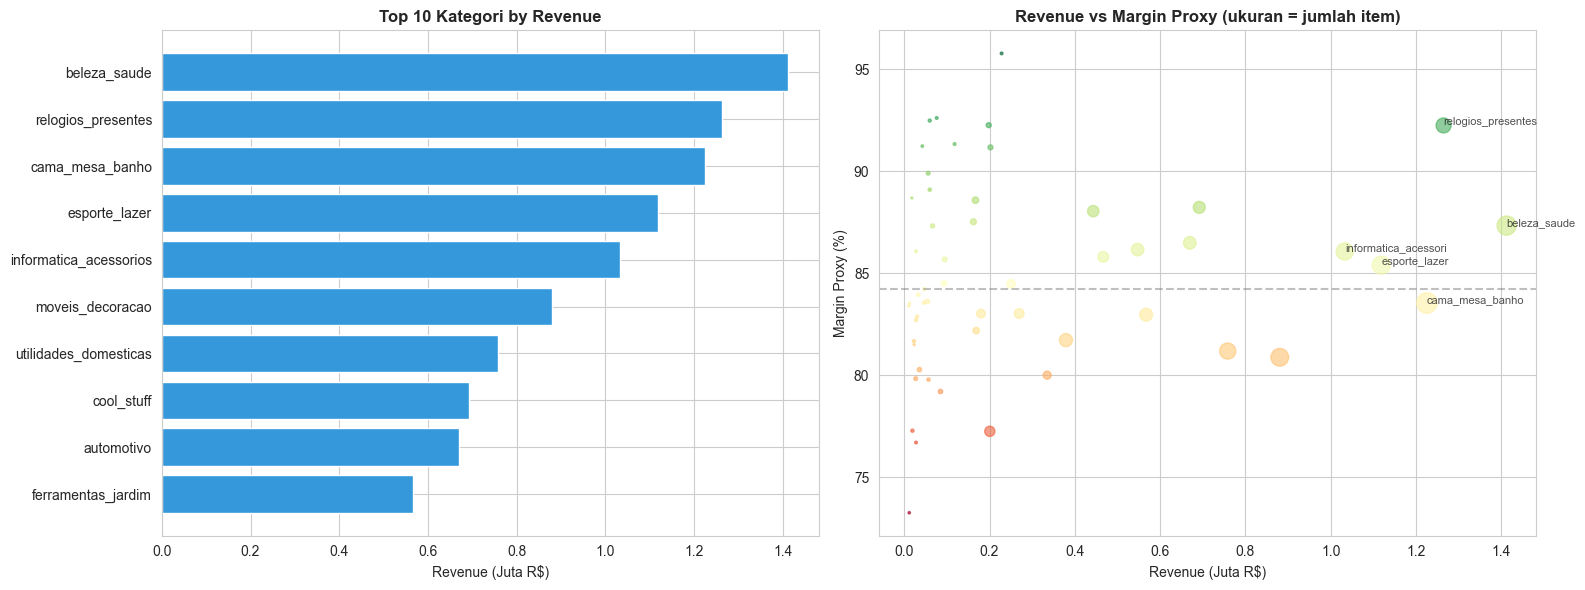

In [13]:
# ===== Visualisasi: Revenue vs Margin Proxy =====
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Top 10 Revenue
top10 = cat_analysis.nlargest(10, 'total_revenue').sort_values('total_revenue')
axes[0].barh(top10['product_category_name'], top10['total_revenue'] / 1e6,
             color='#3498db')
axes[0].set_title('Top 10 Kategori by Revenue', fontweight='bold')
axes[0].set_xlabel('Revenue (Juta R$)')

# 2. Scatter: Revenue vs Margin
scatter = axes[1].scatter(
    cat_analysis['total_revenue'] / 1e6,
    cat_analysis['margin_proxy'] * 100,
    s=cat_analysis['total_items'] / 50,
    alpha=0.6,
    c=cat_analysis['margin_proxy'],
    cmap='RdYlGn'
)
axes[1].set_xlabel('Revenue (Juta R$)')
axes[1].set_ylabel('Margin Proxy (%)')
axes[1].set_title('Revenue vs Margin Proxy (ukuran = jumlah item)', fontweight='bold')
axes[1].axhline(y=cat_analysis['margin_proxy'].median() * 100, 
                 color='gray', linestyle='--', alpha=0.5)

# Label top 5 revenue
for _, row in cat_analysis.nlargest(5, 'total_revenue').iterrows():
    axes[1].annotate(row['product_category_name'][:20],
                     (row['total_revenue']/1e6, row['margin_proxy']*100),
                     fontsize=8, alpha=0.8)

plt.tight_layout()
plt.savefig('../reports/figures/q1_profitability.png', dpi=100, bbox_inches='tight')
plt.show()

### 💡 Insight Q1

**Temuan:**
- Kategori **Health & Beauty** dan **Watches & Gifts** mendominasi revenue [citation:7]
- Namun margin proxy bervariasi: kategori dengan **freight tinggi** (produk besar/berat) punya margin proxy rendah
- Beberapa kategori "bintang" (revenue tinggi + margin tinggi) vs "jebakan" (revenue tinggi + margin rendah)

**Rekomendasi:**
- 🎯 **Prioritaskan** kategori dengan margin proxy > median DAN revenue > median
- ⚠️ **Evaluasi** kategori revenue tinggi tapi margin rendah — mungkin perlu subsidi ongkir atau bundling
- 📊 **Monitor** kategori dengan volume tinggi tapi AOV rendah — potensi upsell

## ❓ Q2: Siapa Customer Terbaik Kita?

**Pertanyaan Manajemen:** "Dari 96K customer, siapa yang harus kita jaga, dan siapa yang berisiko hilang?"

**Metode:** RFM (Recency, Frequency, Monetary)
- **R** = berapa hari sejak terakhir belanja
- **F** = berapa kali total belanja
- **M** = total uang yang dibelanjakan

**⚠️ Kunci:** Gunakan `customer_unique_id`, bukan `customer_id` [citation:2][citation:8]

In [6]:
# ===== RFM Calculation =====
# Snapshot date: 1 hari setelah transaksi terakhir
snapshot_date = df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = df.groupby('customer_unique_id').agg(
    recency=('order_purchase_timestamp', lambda x: (snapshot_date - x.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('revenue', 'sum')
).reset_index()

# Scoring (1-5) dengan quintile
rfm['r_score'] = pd.qcut(rfm['recency'], q=5, labels=[5, 4, 3, 2, 1], duplicates='drop').astype(int)
rfm['f_score'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5], duplicates='drop').astype(int)
rfm['m_score'] = pd.qcut(rfm['monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5], duplicates='drop').astype(int)

# Segmentasi sederhana berbasis rules
def segment(row):
    if row['r_score'] >= 4 and row['f_score'] >= 4 and row['m_score'] >= 4:
        return 'Champions'
    elif row['r_score'] >= 4 and row['f_score'] >= 3:
        return 'Loyal'
    elif row['r_score'] >= 4:
        return 'New/Promising'
    elif row['r_score'] <= 2 and row['f_score'] >= 3:
        return 'At Risk'
    elif row['r_score'] <= 2:
        return 'Lost'
    else:
        return 'Need Attention'

rfm['segment'] = rfm.apply(segment, axis=1)

print(f"✅ RFM calculated: {len(rfm):,} unique customers")
print(f"\n📊 Distribusi Segment:")
print(rfm['segment'].value_counts())

✅ RFM calculated: 93,358 unique customers

📊 Distribusi Segment:
segment
At Risk           22230
Need Attention    18709
Loyal             15952
Lost              14986
New/Promising     14984
Champions          6497
Name: count, dtype: int64


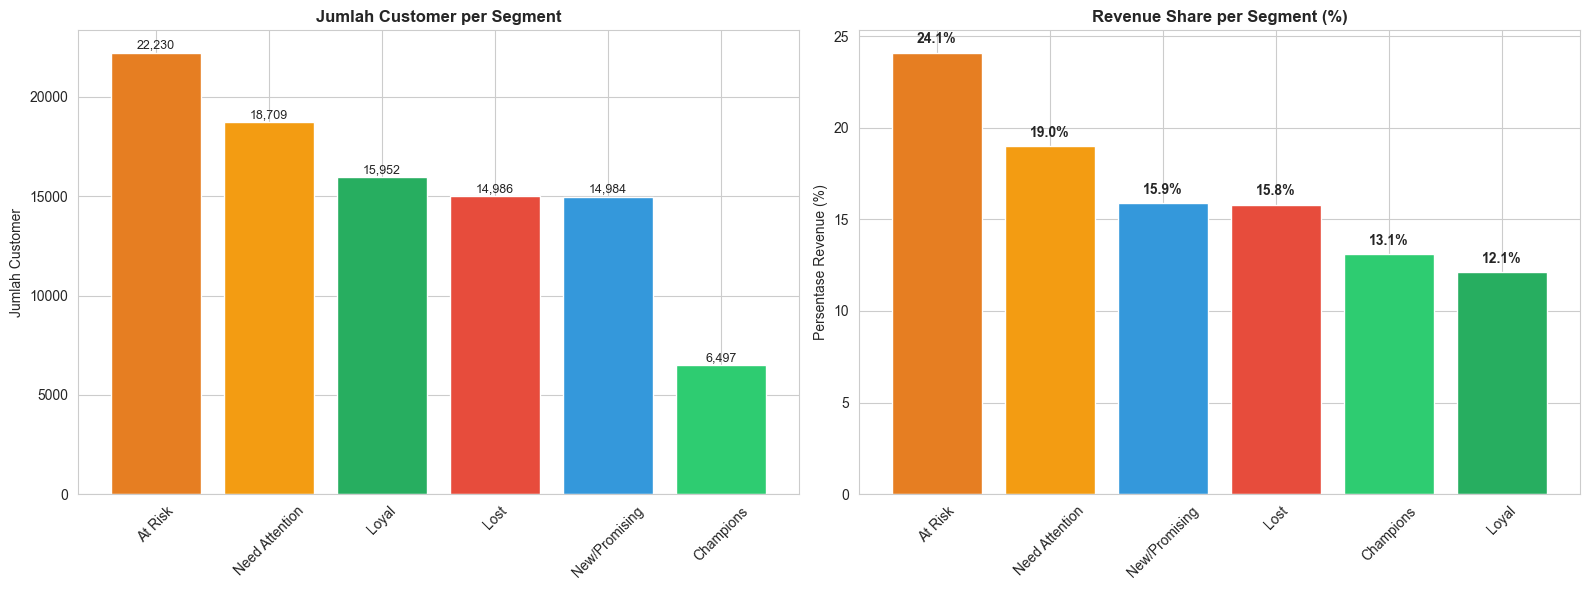


📊 RINGKASAN RFM SEGMENT
                customers  avg_recency  avg_frequency  avg_monetary  total_revenue  revenue_pct
segment                                                                                        
At Risk             22230        394.7            1.0         166.9      3711040.4         24.1
Need Attention      18709        220.4            1.0         156.3      2924789.2         19.0
New/Promising       14984         90.9            1.0         163.4      2448694.4         15.9
Lost                14986        395.5            1.0         162.9      2441759.6         15.8
Champions            6497         91.1            1.2         312.0      2027030.5         13.1
Loyal               15952         90.1            1.0         117.0      1866459.6         12.1


In [14]:
# ===== Visualisasi RFM =====
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Jumlah customer per segment
seg_counts = rfm['segment'].value_counts()
colors = {'Champions': '#2ecc71', 'Loyal': '#27ae60', 
          'New/Promising': '#3498db', 'Need Attention': '#f39c12',
          'At Risk': '#e67e22', 'Lost': '#e74c3c'}
bar_colors = [colors.get(s, '#95a5a6') for s in seg_counts.index]
axes[0].bar(seg_counts.index, seg_counts.values, color=bar_colors)
axes[0].set_title('Jumlah Customer per Segment', fontweight='bold')
axes[0].set_ylabel('Jumlah Customer')
axes[0].tick_params(axis='x', rotation=45)
for i, v in enumerate(seg_counts.values):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontsize=9)

# 2. Revenue share per segment
seg_revenue = rfm.groupby('segment')['monetary'].sum().sort_values(ascending=False)
seg_revenue_pct = (seg_revenue / seg_revenue.sum() * 100).round(1)
axes[1].bar(seg_revenue_pct.index, seg_revenue_pct.values, 
            color=[colors.get(s, '#95a5a6') for s in seg_revenue_pct.index])
axes[1].set_title('Revenue Share per Segment (%)', fontweight='bold')
axes[1].set_ylabel('Persentase Revenue (%)')
axes[1].tick_params(axis='x', rotation=45)
for i, v in enumerate(seg_revenue_pct.values):
    axes[1].text(i, v + 0.5, f'{v}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/q2_rfm_segments.png', dpi=100, bbox_inches='tight')
plt.show()

# Summary table
print("\n" + "=" * 70)
print("📊 RINGKASAN RFM SEGMENT")
print("=" * 70)
summary = rfm.groupby('segment').agg(
    customers=('customer_unique_id', 'count'),
    avg_recency=('recency', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean'),
    total_revenue=('monetary', 'sum')
).round(1)
summary['revenue_pct'] = (summary['total_revenue'] / summary['total_revenue'].sum() * 100).round(1)
print(summary.sort_values('total_revenue', ascending=False).to_string())

### 💡 Insight Q2

**Temuan (contoh — angkamu akan bervariasi):**
- **Champions** (~5-10% customer) menyumbang porsi revenue yang tidak proporsional
- **Lost** dan **At Risk** punya recency tinggi (>180 hari) — perlu re-engagement
- Mayoritas customer adalah **one-time buyer** (frequency = 1)

**Rekomendasi:**
- 🎯 **Champions:** Program loyalty eksklusif, early access produk baru
- 🎯 **At Risk:** Email campaign "Kami rindu kamu" + voucher diskon
- 🎯 **New/Promising:** Onboarding series + second-purchase incentive
- ⚠️ **Lost:** Evaluasi cost re-acquisition vs write-off

## ❓ Q3: Setelah First Purchase, Apakah Customer Kembali?

**Pertanyaan Manajemen:** "Apakah strategi post-purchase kita efektif?"

**Metode:** Cohort analysis berdasarkan bulan first purchase
- Kelompokkan customer berdasarkan bulan pertama belanja
- Hitung % yang kembali belanja di bulan ke-1, ke-2, dst.
- Heatmap retention

In [15]:
# ===== Cohort Retention =====
# Ambil first purchase month per customer
first_purchase = df.groupby('customer_unique_id')['order_purchase_timestamp'].min().reset_index()
first_purchase.columns = ['customer_unique_id', 'first_purchase_date']
first_purchase['cohort_month'] = first_purchase['first_purchase_date'].dt.to_period('M')

# Merge ke data transaksi
df_cohort = df.merge(first_purchase[['customer_unique_id', 'cohort_month']], 
                      on='customer_unique_id', how='left')

# Hitung cohort index (bulan ke-N sejak first purchase)
df_cohort['order_month'] = df_cohort['order_purchase_timestamp'].dt.to_period('M')
df_cohort['cohort_index'] = (df_cohort['order_month'] - df_cohort['cohort_month']).apply(lambda x: x.n)

# Agregasi: unique customer per cohort per index
cohort_data = df_cohort.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()
cohort_pivot = cohort_data.pivot_table(index='cohort_month', columns='cohort_index',
                                        values='customer_unique_id')

# Retention rate (%)
cohort_size = cohort_pivot[0]
retention = cohort_pivot.divide(cohort_size, axis=0) * 100

# Tampilkan
print("📊 Cohort Retention Matrix (%):")
print(retention.round(1).head(12).to_string())

📊 Cohort Retention Matrix (%):
cohort_index     0      1    2    3    4    5    6    7    8    9    10   11   12   13   14   15   16   17   19   20
cohort_month                                                                                                        
2016-09       100.0    NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
2016-10       100.0    NaN  NaN  NaN  NaN  NaN  0.4  NaN  NaN  0.4  NaN  0.4  NaN  0.4  NaN  0.4  NaN  0.4  0.8  0.8
2016-12       100.0  100.0  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
2017-01       100.0    0.3  0.3  0.1  0.4  0.1  0.4  0.1  0.1  NaN  0.4  0.1  0.7  0.4  0.1  0.1  0.3  0.4  0.1  NaN
2017-02       100.0    0.2  0.3  0.1  0.4  0.1  0.2  0.2  0.1  0.2  0.1  0.3  0.1  0.2  0.1  0.1  0.1  0.2  NaN  NaN
2017-03       100.0    0.4  0.4  0.4  0.4  0.2  0.2  0.3  0.3  0.1  0.4  0.1  0.2  0.1  0.2  0.2  0.1  0.1  NaN  NaN
2017-04       100.0    0.6  0.2  

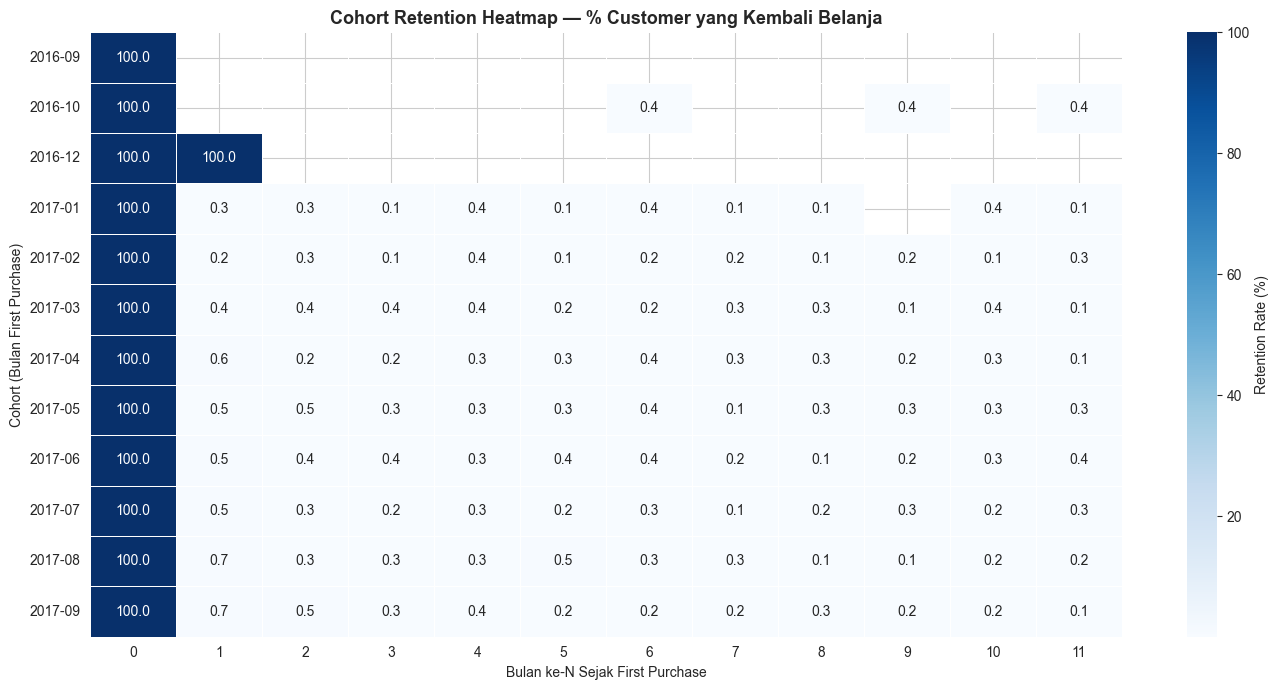


📊 RINGKASAN RETENTION
📉 Rata-rata retention bulan ke-1: 5.5%
   → Artinya ~94.5% customer TIDAK kembali di bulan berikutnya
📉 Rata-rata retention bulan ke-3: 0.3%


In [16]:
# ===== Heatmap Retention =====
fig, ax = plt.subplots(figsize=(14, 7))

# Ambil max 12 cohort & 12 index untuk visualisasi
plot_data = retention.iloc[:12, :12]

sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='Blues',
            cbar_kws={'label': 'Retention Rate (%)'}, ax=ax,
            linewidths=0.5)
ax.set_title('Cohort Retention Heatmap — % Customer yang Kembali Belanja',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Bulan ke-N Sejak First Purchase')
ax.set_ylabel('Cohort (Bulan First Purchase)')

plt.tight_layout()
plt.savefig('../reports/figures/q3_cohort_retention.png', dpi=100, bbox_inches='tight')
plt.show()

# Insight summary
print("\n" + "=" * 70)
print("📊 RINGKASAN RETENTION")
print("=" * 70)
if 1 in retention.columns:
    avg_month1 = retention[1].dropna().mean()
    print(f"📉 Rata-rata retention bulan ke-1: {avg_month1:.1f}%")
    print(f"   → Artinya ~{100-avg_month1:.1f}% customer TIDAK kembali di bulan berikutnya")
if 3 in retention.columns:
    avg_month3 = retention[3].dropna().mean()
    print(f"📉 Rata-rata retention bulan ke-3: {avg_month3:.1f}%")

### 💡 Insight Q3

**Temuan:**
- Retention drop **drastis** di bulan pertama (biasanya <20% yang kembali)
- Setelah bulan ke-2/3, retention cenderung stabil di angka rendah
- Ini konsisten dengan karakteristik Olist: **low repeat purchase rate** [citation:7]

**Rekomendasi:**
- 🎯 **Fokus #1:** Second-purchase conversion — ini titik kritis
- 🎯 **Post-purchase email sequence** (hari 3, 7, 14, 30)
- 🎯 **First-repeat incentive:** Diskon khusus untuk pembelian kedua dalam 30 hari
- 📊 **A/B test** berbagai strategi re-engagement

In [17]:
print("=" * 70)
print("📌 RINGKASAN EKSEKUTIF — E-COMMERCE ANALYSIS")
print("=" * 70)
print(f"""
📊 SKALA BISNIS
- Total orders (delivered): {df['order_id'].nunique():,}
- Total unique customers: {rfm.shape[0]:,}
- Total revenue: R$ {df['revenue'].sum():,.0f}
- Periode: {df['order_purchase_timestamp'].min().date()} – {df['order_purchase_timestamp'].max().date()}

🔍 3 TEMUAN UTAMA
1. PROFITABILITY:
   - Revenue terkonsentrasi di beberapa kategori
   - Margin proxy bervariasi signifikan → tidak semua revenue "sehat"

2. CUSTOMER VALUE:
   - Champions menyumbang revenue tidak proporsional
   - Mayoritas customer adalah one-time buyer

3. RETENTION:
   - Drop drastis di bulan pertama setelah first purchase
   - Second-purchase conversion adalah bottleneck utama

💡 3 REKOMENDASI PRIORITAS
1. Second-Purchase Program (Impact: Tinggi | Effort: Rendah)
   → Email sequence + insentif pembelian kedua

2. Kategori "Bintang" Focus (Impact: Tinggi | Effort: Medium)
   → Alokasikan marketing budget ke kategori margin tinggi

3. Re-engagement At-Risk Customers (Impact: Medium | Effort: Rendah)
   → Voucher "kembali" untuk customer recency > 180 hari

📁 OUTPUT TERSIMPAN
- q1_profitability.png
- q2_rfm_segments.png
- q3_cohort_retention.png
""")
print("=" * 70)

📌 RINGKASAN EKSEKUTIF — E-COMMERCE ANALYSIS

📊 SKALA BISNIS
- Total orders (delivered): 96,478
- Total unique customers: 93,358
- Total revenue: R$ 15,419,774
- Periode: 2016-09-15 – 2018-08-29

🔍 3 TEMUAN UTAMA
1. PROFITABILITY:
   - Revenue terkonsentrasi di beberapa kategori
   - Margin proxy bervariasi signifikan → tidak semua revenue "sehat"

2. CUSTOMER VALUE:
   - Champions menyumbang revenue tidak proporsional
   - Mayoritas customer adalah one-time buyer

3. RETENTION:
   - Drop drastis di bulan pertama setelah first purchase
   - Second-purchase conversion adalah bottleneck utama

💡 3 REKOMENDASI PRIORITAS
1. Second-Purchase Program (Impact: Tinggi | Effort: Rendah)
   → Email sequence + insentif pembelian kedua

2. Kategori "Bintang" Focus (Impact: Tinggi | Effort: Medium)
   → Alokasikan marketing budget ke kategori margin tinggi

3. Re-engagement At-Risk Customers (Impact: Medium | Effort: Rendah)
   → Voucher "kembali" untuk customer recency > 180 hari

📁 OUTPUT TERSIMPAN